In [1]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

from qiskit_aer import Aer
from qiskit.tools.visualization import plot_histogram
from qiskit.circuit.library import TwoLocal, EfficientSU2
from qiskit_optimization.applications import Maxcut
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE, NumPyMinimumEigensolver
from qiskit.algorithms.optimizers import SPSA
from qiskit.utils import algorithm_globals
from qiskit.primitives import Sampler
from qiskit_optimization.algorithms import MinimumEigenOptimizer

In [2]:
import matplotlib
print(np.__version__)
print(matplotlib.__version__)

1.26.3
3.8.0


First define the graph and related functions

In [3]:
# Generating a graph of 4 nodes
def draw_graph(G, colors, pos, ax=None):
    default_axes = plt.axes(frameon=True) if ax is None else ax
    nx.draw_networkx(G, node_color=colors, node_size=600, alpha=0.8, ax=default_axes, pos=pos)
    edge_labels = nx.get_edge_attributes(G, "weight")
    nx.draw_networkx_edge_labels(G, pos=pos, edge_labels=edge_labels)

def compute_matrix(n, G):
    # Computing the weight matrix from the random graph
    w = np.zeros([n, n])
    for i in range(n):
        for j in range(n):
            temp = G.get_edge_data(i, j, default=0)
            if temp != 0:
                w[i, j] = 1
    return w

def color_graph(bitstring, n, m, H, posH, ax=None):
    #print(bitstring)
    colors = ["r" for node in range(m)]
    for k in range(n*m):
        i = k // m  # Integer division to retrieve the i value
        j = k % m   # Modulus operation to retrieve the j value
        if bitstring[k] == 1:
            #print(f"coloring {j}!")
            colors[j] = "b"
    draw_graph(H, colors, posH, ax)

Define the translation from graph matrices to terms

In [4]:
def expand_arithmetic_function(mat1, mat2, n, m):
    linear = []
    quadratic = []
    cubic = []

    penalty = n

    def translate(i, j):
        return (i*m+j)

    # Define your arithmetic function here
    sum = 0
    for i in range(n):
        for u in range(m):
            linear.append((translate(i, u), -1))

    #print(f"Sum after first term: {sum}")

    # SECOND TERM (EXPANDED):
    sum2 = 0
    for v in range(m):
        inner = 0
        for i in range(n):
            for k in range(n):
                quadratic.append( ( (translate(i, v), translate(k, v) ), 1) )   # ( (var1, var2),  coeff )
        
        for i in range(n):
            linear.append((translate(i, v), -1))
    

    sum2 = 0
    # THIRD TERM (CHECKS THAT NUMBER OF OUTGOING EDGES OF EACH VERTEX U IS EQUAL TO OUTGOING EDGES OF EACH VERTEX I):
    for u in range(m):
        for i in range(n):
            for j in range(n):
                # Add the linear terms:
                linear.append((translate(i, u), penalty*mat1[i][j]*mat1[i][j]))

                for v in range(m):
                    # Add quadratic terms:
                    quadratic.append( ( (translate(j,v), translate(i, u) ), -1*2*penalty*mat1[i][j]*mat2[u][v]) )
                
                for v in range(m):
                    for k in range(m):
                        # Add cubic terms:
                        cubic.append( ( ( translate(j,v), translate(j, k), translate(i,u) ), penalty*mat2[u][v]*mat2[u][k] ) )
            

    # FOURTH TERM (CHECKS THAT NUMBER OF INCOMING EDGES OF EACH VERTEX U IS EQUAL TO OUTGOING EDGES OF EACH VERTEX I):
    for u in range(m):
        for i in range(n):
            for j in range(n):
                # Add the linear terms:
                linear.append((translate(i, u), penalty*mat1[j][i]*mat1[j][i]))

                for v in range(m):
                    # Add quadratic terms:
                    quadratic.append( ( (translate(j,v), translate(i, u) ), -1*2*penalty*mat1[j][i]*mat2[v][u]) )
                
                for v in range(m):
                    for k in range(m):
                        # Add cubic terms:
                        cubic.append( ( ( translate(j,v), translate(j, k), translate(i,u) ), penalty*mat2[v][u]*mat2[k][u] ) )
    
    return linear, quadratic, cubic

def clean_coefficients(linear, quadratic, cubic):
    def drop(list):
        to_remove = []
        for idx, (term, coeff) in enumerate(list):
            if coeff == 0:
                to_remove.append((term, coeff))
        
        for item in to_remove:
            list.remove(item)
        return list
    
    linear = drop(linear)
    quadratic = drop(quadratic)
    cubic = drop(cubic)
    
    return linear, quadratic, cubic

from itertools import product
from collections import Counter

def collect_terms(linear, quadratic, cubic):

    def combine(tuple_list):
        combined_tuples = {}
        
        for tpl, coeff in tuple_list:
            # Convert the tuple to a hashable format using sorted tuple of its Counter elements
            if isinstance(tpl, int):
                tpl = (tpl,)
            hashable_tpl = tuple(sorted(Counter(tpl).items()))
            #print(f"before: {tpl}, after: {hashable_tpl}")
            # Check if the hashable tuple already exists in the dictionary
            if hashable_tpl in combined_tuples:
                # Accumulate the coefficient for the existing tuple
                combined_tuples[hashable_tpl] += coeff
            else:
                # Create a new entry in the dictionary
                combined_tuples[hashable_tpl] = coeff
        
        # Convert the dictionary back to the original format of list of tuples
        reduced_list = [( tuple(x for x, count in dict_key for _ in range(count)) , coeff) for dict_key, coeff in combined_tuples.items()]
        
        return reduced_list

    
    collected_linear_terms = combine(linear)
    collected_quadratic_terms = combine(quadratic)
    collected_cubic_terms = combine(cubic)

    return collected_linear_terms, collected_quadratic_terms, collected_cubic_terms
    
def produce_terms_from_graphs(mat1, mat2, n, m):
    linear, quadratic, cubic = expand_arithmetic_function(mat1, mat2, n, m)
    linear, quadratic, cubic = clean_coefficients(linear, quadratic, cubic)
    linear, quadratic, cubic = collect_terms(linear, quadratic, cubic)
    #print(f"Size: {len(linear)}, linear terms: {linear}")
    #print(f"Size: {len(quadratic)}, quadratic terms: {quadratic}")
    #print(f"Size: {len(cubic)}, cubic terms: {cubic}")
    return linear, quadratic, cubic

Define the quantum components to compute the optimal solution

In [5]:
from typing import Dict, List, Optional, Tuple, Union, cast

class CubicProgram:

    def __init__(self, name: str = "") -> None:
        self.linear = []
        self.quadratic = []
        self.cubic = []
        self.num_vars = 0

    def get_num_vars(self):
        return self.num_vars
    
    def set_num_vars(self, n):
        self.num_vars = n

    def set_linear(self, linear_vars_list):
        self.linear = linear_vars_list
    
    def set_quadratic(self, quadratic_vars_list):
        self.quadratic = quadratic_vars_list

    def set_cubic(self, cubic_vars_list):
        self.cubic = cubic_vars_list
    
from qiskit_optimization.problems.quadratic_program import QuadraticProgram
from qiskit.quantum_info import Pauli, SparsePauliOp
from qiskit.quantum_info import Pauli
import numpy as np

def to_cubic_ising(cubic_prog: CubicProgram) -> SparsePauliOp:
    num_vars = cubic_prog.get_num_vars()
    zero = np.zeros(num_vars, dtype=bool)
    cubic_list = []

    offset = 0
    sense = 1

    # convert linear parts of the objective function into Hamiltonian.
    for idx, coef in cubic_prog.linear:
        z_p = zero.copy()
        weight = coef*sense / 2
        z_p[idx] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
        offset += weight

    # convert quadratic parts of the objective function into Hamiltonian.
    for (i, j), coeff in cubic_prog.quadratic:
        weight = coeff*sense / 4

        if (i == j):
            offset += weight
        else:
            z_p = zero.copy()
            z_p[i] = True
            z_p[j] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), weight))
        
        z_p = zero.copy()
        z_p[i] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        z_p = zero.copy()
        z_p[j] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        offset += weight

    # convert cubic parts of the objective function into Hamiltonian.
    for (i, j, k), coeff in cubic_prog.cubic:
        weight = coeff*sense / 8

        # consider cubic terms:
        if i == j and j == k:
            # a*a*a = Ia = a
            z_p[i] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
        else:
            if i == j and j != k:
                # Then we have something like a^2c = Ic = c (quadratic case where i != j):
                z_p = zero.copy()
                z_p[k] = True
                cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
            else:
                if i != j and i == k:
                    # a^2b = Ib = b:
                    z_p = zero.copy()
                    z_p[j] = True
                    cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
                else:
                    if i != j and j == k:
                        # aI = a
                        z_p = zero.copy()
                        z_p[i] = True
                        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
                    else:
                        # i != j != k: abc
                        z_p = zero.copy()
                        z_p[i] = True
                        z_p[j] = True
                        z_p[k] = True
                        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))


        # consider quadratic terms:
        if (i == j):
            offset += weight
        else:
            z_p = zero.copy()
            z_p[i] = True
            z_p[j] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), weight))
        
        if (i == k):
            offset += weight
        else:
            z_p = zero.copy()
            z_p[i] = True
            z_p[k] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), weight))
        
        if (j == k):
            offset += weight
        else:
            z_p = zero.copy()
            z_p[j] = True
            z_p[k] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), weight))
        
        # consider linear terms
        z_p = zero.copy()
        z_p[i] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        z_p = zero.copy()
        z_p[j] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        z_p = zero.copy()
        z_p[k] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        # consider constant term:
        offset += weight

    # combine all Pauli terms
    #print(cubic_list)
    if cubic_list:
        # Remove paulis whose coefficients are zeros.
        qubit_op = sum(cubic_list).simplify(atol=0)
    else:
        # If there is no variable, we set num_nodes=1 so that qubit_op should be an operator.
        # If num_nodes=0, I^0 = 1 (int).
        num_vars = max(1, num_vars)
        qubit_op = SparsePauliOp("I" * num_vars, 0)

    return qubit_op, offset

from qiskit.quantum_info import Statevector
from qiskit.result import QuasiDistribution
from collections import OrderedDict

def sample_most_likely(
    state_vector: Union[QuasiDistribution, Statevector, np.ndarray, Dict]
) -> np.ndarray:
    """Compute the most likely binary string from state vector.

    Args:
        state_vector: state vector or counts or quasi-probabilities.

    Returns:
        binary string as numpy.ndarray of ints.

    Raises:
        ValueError: if state_vector is not QuasiDistribution, Statevector,
            np.ndarray, or dict.
    """
    if isinstance(state_vector, QuasiDistribution):
        print(1)
        probabilities = state_vector.binary_probabilities()
        binary_string = max(probabilities.items(), key=lambda kv: kv[1])[0]
        x = np.asarray([int(y) for y in reversed(list(binary_string))])
        return x
    elif isinstance(state_vector, Statevector):
        probabilities = state_vector.probabilities()
        #print(np.abs(probabilities))
        n = state_vector.num_qubits
        k = np.argmax(np.abs(probabilities))
        print(f"The largest probability: {np.max(np.abs(probabilities))}")
        x = np.zeros(n)
        for i in range(n):
            x[i] = k % 2
            k >>= 1
        return x
    elif isinstance(state_vector, (OrderedDict, dict)):
        print(3)
        # get the binary string with the largest count
        binary_string = max(state_vector.items(), key=lambda kv: kv[1])[0]
        x = np.asarray([int(y) for y in reversed(list(binary_string))])
        return x
    elif isinstance(state_vector, np.ndarray):
        print(4)
        n = int(np.log2(state_vector.shape[0]))
        k = np.argmax(np.abs(state_vector))
        x = np.zeros(n)
        for i in range(n):
            x[i] = k % 2
            k >>= 1
        return x
    else:
        raise ValueError(
            "state vector should be QuasiDistribution, Statevector, ndarray, or dict. "
            f"But it is {type(state_vector)}."
        )

from qiskit.utils import algorithm_globals
from qiskit.algorithms.optimizers import SPSA, SLSQP
from qiskit.circuit.library import TwoLocal, EfficientSU2
from qiskit.primitives import Sampler
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE, NumPyMinimumEigensolver, VQE
from qiskit.primitives import Estimator 
def VQE_run(cubic_problem):
    print("\n\nVQE RESULTS:\n")
    qubitOp, offset = to_cubic_ising(cubic_problem)

    estimator = Estimator() 
    optimizer = SLSQP() 
    ansatz = EfficientSU2(qubitOp.num_qubits, su2_gates="ry", reps=5, entanglement="linear")
    
    vqe = VQE(estimator, ansatz, optimizer) 
    result = vqe.compute_minimum_eigenvalue(operator=qubitOp) 
    eigenvalue = result.eigenvalue

    # run VQE:
    # print(result.cost_function_evals)
    # print(result)
    #print(sample_most_likely(result.eigenstate))
    print(f"Energy: {result.eigenvalue}")
    print(f"Optimal value: {result.eigenvalue + offset}")

    # Finding the bitstring:
    from qiskit import Aer, QuantumCircuit, transpile, assemble

    optimal_parameters = result.optimal_parameters
    optimal_circuit = ansatz.assign_parameters(optimal_parameters)

    # Execute the optimal circuit to obtain the final statevector
    backend = Aer.get_backend('statevector_simulator')
    final_state = backend.run(transpile(optimal_circuit, backend)).result().get_statevector()

    # The optimal eigenstate is directly obtained from the final statevector
    optimal_eigenstate = final_state

    #print("Optimal Eigenstate:", optimal_eigenstate)

    bit_string = sample_most_likely(optimal_eigenstate)
    print(f"Solution: {bit_string}")
    return bit_string, result


def numpy_eigensolver_run(cubic_problem):
    print("\n\nNUMPY EIGENSOLVER RESULTS:\n")
    qubitOp, offset = to_cubic_ising(cubic_problem)

    ee = NumPyMinimumEigensolver()
    result = ee.compute_minimum_eigenvalue(qubitOp)

    x = sample_most_likely(result.eigenstate)
    print("Energy:", result.eigenvalue.real)
    print("Optimal Value:", result.eigenvalue.real + offset)
    print("Solution:", x)
    return x

NameError: name 'result' is not defined

None
None


VQE RESULTS:

Energy: -24.99990995193195
Optimal value: -3.9999099519319508
The largest probability: 0.9999869410498978
Solution: [0. 1. 0. 0. 1. 0. 0. 0. 1. 0. 0. 1.]


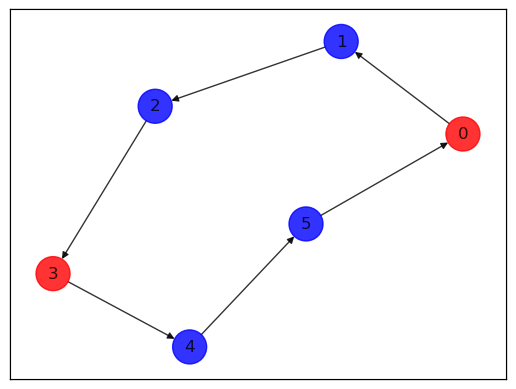

In [145]:
# Main program:
# 1. Define graph
# 2. Compute terms
# 3. Run VQE
# 4. Display on graph

# ----------------------- 1 ------------------------------
# Define the graphs:
# Target graph
m = 6  # Number of nodes in graph
H = nx.DiGraph()
H.add_nodes_from(np.arange(0, m, 1))
elistH = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0)]
# tuple is (i,j,weight) where (i,j) is the edge
H.add_edges_from(elistH)

colorsH = ["r" for node in H.nodes()]
posH = nx.spring_layout(H)

# Pattern graph:
n = 2
G = nx.DiGraph()
G.add_nodes_from(np.arange(0, n, 1))
elistG = [(0, 1)]
G.add_edges_from(elistG)
colorsG = ["r" for node in G.nodes()]
posG = nx.spring_layout(H)

print(draw_graph(G, colorsG, posG))
print(draw_graph(H, colorsH, posH))

# ----------------------- 2 ------------------------------

# Extract the terms
linear, quadratic, cubic = produce_terms_from_graphs(compute_matrix(n, G), compute_matrix(m, H), n, m)

# ----------------------- 3 ------------------------------

# Define cubic problem:
cubic_instance = CubicProgram()
cubic_instance.set_num_vars(n*m)
cubic_instance.set_linear(linear)
cubic_instance.set_quadratic(quadratic)
cubic_instance.set_cubic(cubic)

# Run VQE:
bitstring, result = VQE_run(cubic_instance)

# ----------------------- 4 ------------------------------
color_graph(bitstring, n, m, H, posH)

In [154]:
print("\n\nVQE RESULTS:\n")
qubitOp, offset = to_cubic_ising(cubic_instance)

estimator = Estimator() 
optimizer = SLSQP() 
ansatz = EfficientSU2(qubitOp.num_qubits, su2_gates="ry", reps=5, entanglement="linear")

vqe = VQE(estimator, ansatz, optimizer) 
result = vqe.compute_minimum_eigenvalue(operator=qubitOp) 
eigenvalue = result.eigenvalue

# run VQE:
# print(result.cost_function_evals)
# print(result)
#print(sample_most_likely(result.eigenstate))
print(f"Energy: {result.eigenvalue}")
print(f"Optimal value: {result.eigenvalue + offset}")

# Finding the bitstring:
from qiskit import Aer, QuantumCircuit, transpile, assemble

optimal_parameters = result.optimal_parameters
optimal_circuit = ansatz.assign_parameters(optimal_parameters)

# Execute the optimal circuit to obtain the final statevector
backend = Aer.get_backend('statevector_simulator')
final_state = backend.run(transpile(optimal_circuit, backend)).result().get_statevector()

# The optimal eigenstate is directly obtained from the final statevector
optimal_eigenstate = final_state

#print("Optimal Eigenstate:", optimal_eigenstate)

bit_string = sample_most_likely(optimal_eigenstate)
print(f"Solution: {bit_string}")



VQE RESULTS:

Energy: -24.999992595331232
Optimal value: -3.999992595331232
The largest probability: 0.9999994624040106
Solution: [0. 1. 0. 0. 1. 0. 0. 0. 1. 0. 0. 1.]


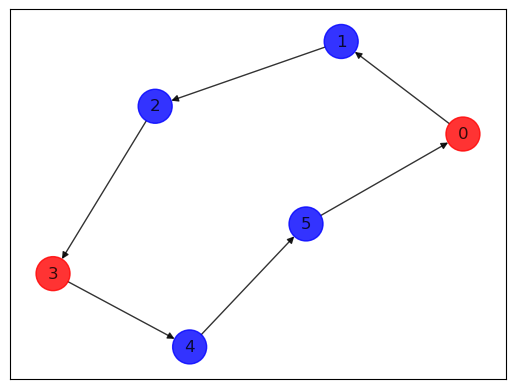

In [155]:
color_graph(bit_string, n, m, H, posH)

In [156]:
optimal_circuit.measure_active()

In [157]:
from qiskit_aer import AerSimulator
aer_simulator = AerSimulator()
qc_compiled = transpile(optimal_circuit, aer_simulator)

In [158]:
job_sim = aer_simulator.run(qc_compiled, shots=100000)

In [159]:
result_sim = job_sim.result()
counts = result_sim.get_counts(qc_compiled)

In [160]:
probabilities = {bitstring: np.sqrt(count/100000) \
                        for bitstring, count in counts.items()}
probabilities

{'100100010010': 1.0}

In [60]:
optimal_parameters
vqe_with_parameters = vqe.ansatz.bind_parameters(vqe.optimal_parameters)
vqe_with_parameters.decompose(reps=3)

AttributeError: 'VQE' object has no attribute 'optimal_parameters'

In [90]:
final_state = backend.run(transpile(optimal_circuit, backend), shots=pow(2, qubitOp.num_qubits)).result()
counts = final_state.get_counts()
final_state.results[0].shots

256

In [83]:
final_state.get_statevector()['00011000']

(0.0008671556313184009+0j)

In [99]:
sum(counts.values())

0.999999999999997

In [100]:
sqrt_probabilities = {bitstring: np.sqrt(count/final_state.results[0].shots) \
                        for bitstring, count in counts.items()}
sum(sqrt_probabilities.values())

0.062754492137997

In [101]:
counts['00011000']

7.51958889e-07

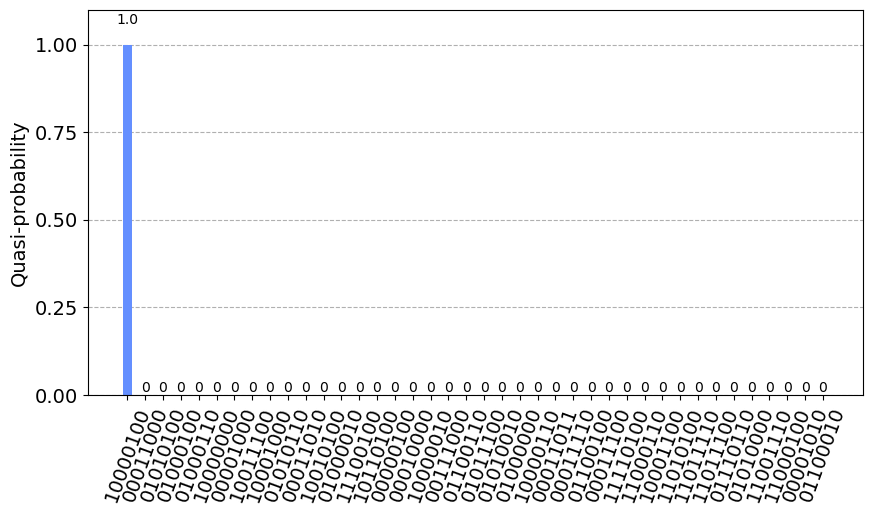

In [103]:
plot_histogram(
    final_state.get_counts(),
    number_to_keep=40,
    sort="value_desc",
    bar_labels=True,
    figsize=(10,5))

In [38]:
from qiskit_aer import AerSimulator

vqe_with_parameters = ansatz.bind_parameters(optimal_parameters)

number_of_shots = 80000
aer_simulator = AerSimulator(method="statevector", shots=number_of_shots)

result = aer_simulator.run(vqe_with_parameters.decompose())

In [39]:
result.result().get_counts()

# # Plot the 40 bitstrings with the highest count.
# plot_histogram(
#     counts,
#     number_to_keep=40,
#     sort="value_desc",
#     bar_labels=False,
#     figsize=(10,5))

QiskitError: 'No counts for experiment "0"'

In [12]:
#print(result)
print(sum(optimal_eigenstate.to_dict().values()))
print(optimal_eigenstate['10000100'])
# print(optimal_eigenstate.binary_probabilities())
# print(optimal_eigenstate[132])
# print(optimal_eigenstate.probabilities()[132])
# print(np.max(np.abs(optimal_eigenstate.probabilities())))

(-0.9978046262627996+0j)
(-0.9999994117833035+0j)


In [15]:
print(result.optimal_point)

[ 1.57112093e+00  1.17432449e-02  2.29753849e-01  6.80889630e-01
 -1.46565512e+00  1.62403438e+00  1.59504510e-02 -1.54135991e+00
  1.57071096e+00 -1.57089605e+00 -1.57066703e+00  1.57057231e+00
  1.57086230e+00 -1.55327854e+00 -1.58843937e+00 -1.63539630e+00
  6.94790176e-01 -3.04360089e+00 -8.35715552e-01 -3.03527428e+00
  4.36879991e-02 -1.55329052e+00 -1.60028459e+00  1.63537689e+00
 -9.14278261e-01 -1.56004011e+00 -1.57079839e+00  1.57079508e+00
 -3.14159265e+00 -2.39873600e+00  1.61312856e+00 -7.83265591e-02
 -2.57890617e-01 -1.62651371e+00  1.57193299e+00 -8.41179755e-01
  1.74050273e-01 -1.57078338e+00  1.57116897e+00 -1.47064031e+00
 -5.79481869e-04 -3.14157653e+00 -7.67767104e-05 -1.57710040e+00
 -1.45796824e+00 -1.52844706e+00 -3.06330651e+00 -3.04171978e+00]


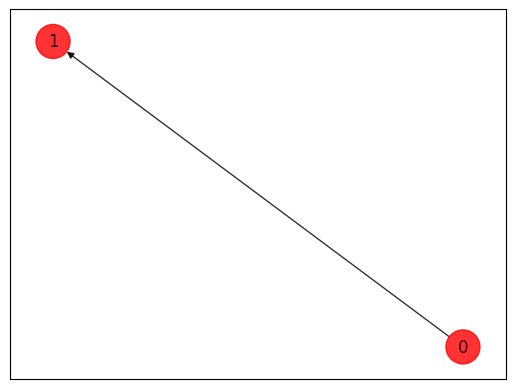

In [61]:
draw_graph(G, colorsG, posG)

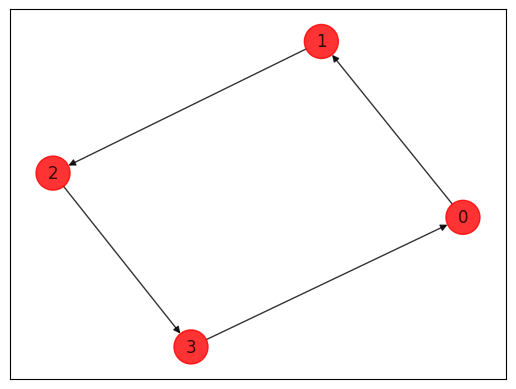

In [62]:
draw_graph(H, colorsH, posH)

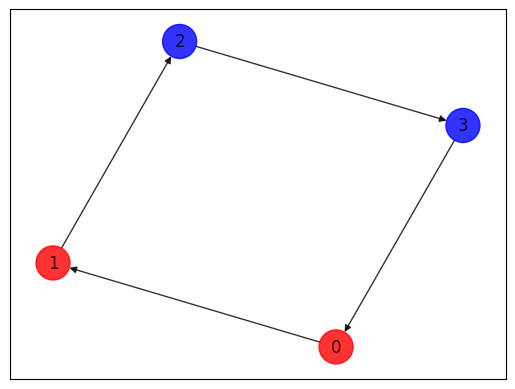

In [54]:
# ----------------------- 4 ------------------------------
color_graph(bitstring, n, m, H)

None
None


VQE RESULTS:

Energy: -22.99999964958893
Optimal value: -3.999999649588929
The largest probability: 0.9999999405049844
Solution: [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0.]


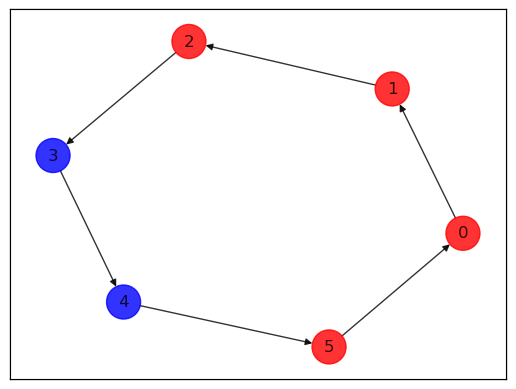

In [5]:
# ----------------------- 1 ------------------------------
# Define the graphs:
# Target graph
m = 6  # Number of nodes in graph
H = nx.DiGraph()
H.add_nodes_from(np.arange(0, m, 1))
elistH = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0)]
H.add_edges_from(elistH)

colorsH = ["r" for node in H.nodes()]
posH = nx.spring_layout(H)

# Pattern graph:
n = 2
G = nx.DiGraph()
G.add_nodes_from(np.arange(0, n, 1))
elistG = [(0, 1)]
G.add_edges_from(elistG)
colorsG = ["r" for node in G.nodes()]
posG = nx.spring_layout(H)

print(draw_graph(G, colorsG, posG))
print(draw_graph(H, colorsH, posH))

# ----------------------- 2 ------------------------------

# Extract the terms
linear, quadratic, cubic = produce_terms_from_graphs(compute_matrix(n, G), compute_matrix(m, H), n, m)

# ----------------------- 3 ------------------------------

# Define cubic problem:
cubic_instance = CubicProgram()
cubic_instance.set_num_vars(n*m)
cubic_instance.set_linear(linear)
cubic_instance.set_quadratic(quadratic)
cubic_instance.set_cubic(cubic)

# Run VQE:
bitstring = VQE_run(cubic_instance)

# ----------------------- 4 ------------------------------
color_graph(bitstring, n, m, H, posH)

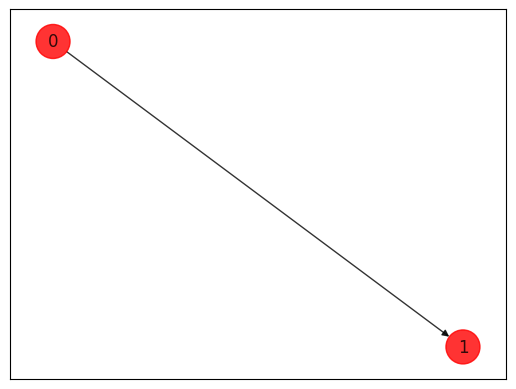

In [71]:
draw_graph(G, colorsG, posG)

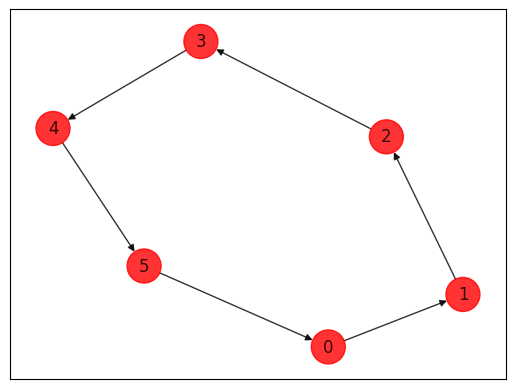

In [72]:
draw_graph(H, colorsH, posH)

None
None
Size: 12, linear terms: [((0,), 4.0), ((1,), 4.0), ((2,), 4.0), ((3,), 4.0), ((4,), 4.0), ((5,), 4.0), ((6,), 4.0), ((7,), 4.0), ((8,), 4.0), ((9,), 4.0), ((10,), 4.0), ((11,), 4.0)]
Size: 42, quadratic terms: [((0, 0), 1), ((0, 1), 2), ((0, 2), 2), ((4, 4), 1), ((4, 5), 2), ((4, 6), 2), ((8, 8), 1), ((8, 9), 2), ((8, 10), 2), ((1, 1), 1), ((1, 2), 2), ((5, 5), 1), ((5, 6), 2), ((9, 9), 1), ((9, 10), 2), ((2, 2), 1), ((6, 6), 1), ((10, 10), 1), ((0, 3), 1), ((1, 3), 1), ((2, 3), 1), ((4, 7), 1), ((5, 7), 1), ((6, 7), 1), ((8, 11), 1), ((9, 11), 1), ((10, 11), 1), ((0, 5), -12.0), ((0, 6), -12.0), ((0, 9), -12.0), ((0, 10), -12.0), ((4, 9), -12.0), ((4, 10), -12.0), ((1, 6), -12.0), ((1, 10), -12.0), ((5, 10), -12.0), ((3, 5), -12.0), ((3, 6), -12.0), ((3, 9), -12.0), ((3, 10), -12.0), ((7, 9), -12.0), ((7, 10), -12.0)]
Size: 138, cubic terms: [((0, 1, 1), 3.0), ((0, 1, 2), 12.0), ((0, 2, 2), 3.0), ((0, 5, 5), 3.0), ((0, 5, 6), 6.0), ((0, 6, 6), 3.0), ((0, 9, 9), 3.0), ((0, 9,

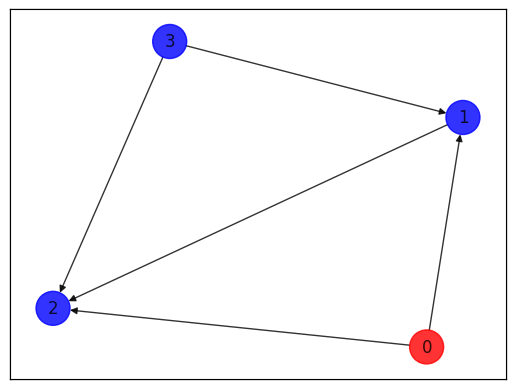

In [5]:
# ----------------------- 1 ------------------------------
# Define the graphs:
# Target graph
m = 4 # Number of nodes in graph
H = nx.DiGraph()
H.add_nodes_from(np.arange(0, m, 1))
elistH = [(0, 1), (0, 2), (1, 2), (3, 1), (3, 2)]
H.add_edges_from(elistH)

colorsH = ["r" for node in H.nodes()]
posH = nx.spring_layout(H)

# Pattern graph:
n = 3
G = nx.DiGraph()
G.add_nodes_from(np.arange(0, n, 1))
elistG = [(0, 1), (0, 2), (1, 2)]
G.add_edges_from(elistG)
colorsG = ["r" for node in G.nodes()]
posG = nx.spring_layout(G)

print(draw_graph(G, colorsG, posG))
print(draw_graph(H, colorsH, posH))

# ----------------------- 2 ------------------------------

# Extract the terms
linear, quadratic, cubic = produce_terms_from_graphs(compute_matrix(n, G), compute_matrix(m, H), n, m)

# ----------------------- 3 ------------------------------

# Define cubic problem:
cubic_instance = CubicProgram()
cubic_instance.set_num_vars(n*m)
cubic_instance.set_linear(linear)
cubic_instance.set_quadratic(quadratic)
cubic_instance.set_cubic(cubic)

# Run VQE:
bitstring = VQE_run(cubic_instance)

# ----------------------- 4 ------------------------------
color_graph(bitstring, n, m, H, posH)

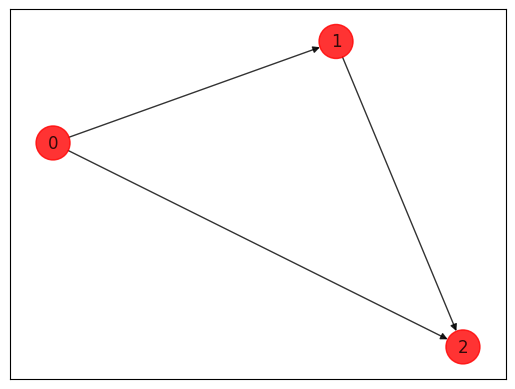

In [74]:
draw_graph(G, colorsG, posG)

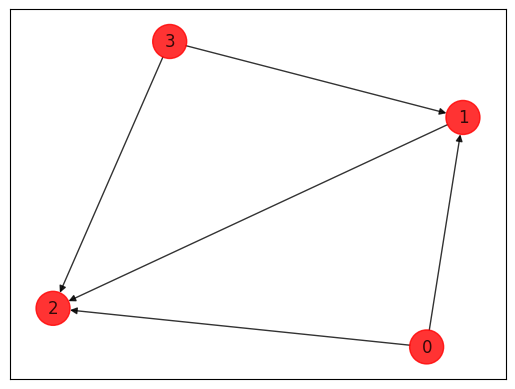

In [6]:
draw_graph(H, colorsH, posH)

None
None


VQE RESULTS:

Energy: -29.999985906904737
Optimal value: -5.999985906904737
The largest probability: 0.9999977969699515
Solution: [1. 0. 0. 0. 1. 0. 0. 1. 1. 0.]


NUMPY EIGENSOLVER RESULTS:

The largest probability: 1.0
Energy: -30.0
Optimal Value: -6.0
Solution: [1. 0. 0. 0. 1. 0. 0. 1. 1. 0.]


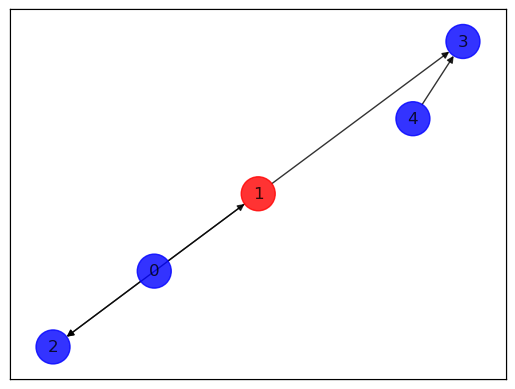

In [7]:
# ----------------------- 1 ------------------------------
# Define the graphs:
# Target graph
m = 5 # Number of nodes in graph
H = nx.DiGraph()
H.add_nodes_from(np.arange(0, m, 1))
elistH = [(0, 1), (0, 2), (1, 2), (1, 3), (4, 3)]
H.add_edges_from(elistH)

colorsH = ["r" for node in H.nodes()]
posH = nx.spring_layout(H)

# Pattern graph:
n = 2
G = nx.DiGraph()
G.add_nodes_from(np.arange(0, n, 1))
elistG = [(0, 1)]
G.add_edges_from(elistG)
colorsG = ["r" for node in G.nodes()]
posG = nx.spring_layout(G)

print(draw_graph(G, colorsG, posG))
print(draw_graph(H, colorsH, posH))

# ----------------------- 2 ------------------------------

# Extract the terms
linear, quadratic, cubic = produce_terms_from_graphs(compute_matrix(n, G), compute_matrix(m, H), n, m)

# ----------------------- 3 ------------------------------

# Define cubic problem:
cubic_instance = CubicProgram()
cubic_instance.set_num_vars(n*m)
cubic_instance.set_linear(linear)
cubic_instance.set_quadratic(quadratic)
cubic_instance.set_cubic(cubic)

# Run VQE:
bitstring1 = VQE_run(cubic_instance)

# Run numpy eigensolver:
bitstring2 = numpy_eigensolver_run(cubic_instance)

# ----------------------- 4 ------------------------------
color_graph(bitstring1, n, m, H, posH)

In [30]:
from qiskit.utils import algorithm_globals
from qiskit.algorithms.optimizers import SPSA, SLSQP
from qiskit.circuit.library import TwoLocal, EfficientSU2
from qiskit.primitives import Sampler
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE, NumPyMinimumEigensolver, VQE
from qiskit.primitives import Estimator 

from qiskit import Aer, QuantumCircuit, transpile, assemble

import timeit

def run_experiment(m, H, posH, n, G):
    overlap = []
    timing = []
    bitstrings = []
    avg_overlap = 0
    avg_timing = 0
    for i in range(20):
        # Extract the terms
        linear, quadratic, cubic = produce_terms_from_graphs(compute_matrix(n, G), compute_matrix(m, H), n, m)

        # Define cubic problem:
        cubic_instance = CubicProgram()
        cubic_instance.set_num_vars(n*m)
        cubic_instance.set_linear(linear)
        cubic_instance.set_quadratic(quadratic)
        cubic_instance.set_cubic(cubic)

        def sample_most_likely(state_vector):
            probabilities = state_vector.probabilities()
            n = state_vector.num_qubits
            k = np.argmax(np.abs(probabilities))
            x = np.zeros(n)
            for i in range(n):
                x[i] = k % 2
                k >>= 1
            return x, np.max(np.abs(probabilities))
        
        # 3. Run VQE
        def run_VQE():
            qubitOp, offset = to_cubic_ising(cubic_instance)
            # run vqe:
            estimator = Estimator() 
            optimizer = SLSQP() 
            ansatz = EfficientSU2(qubitOp.num_qubits, su2_gates="ry", reps=2, entanglement="linear")
            vqe = VQE(estimator, ansatz, optimizer) 
            result = vqe.compute_minimum_eigenvalue(operator=qubitOp) 
            eigenvalue = result.eigenvalue
            # Find the bitstring:
            optimal_parameters = result.optimal_parameters
            optimal_circuit = ansatz.assign_parameters(optimal_parameters)
            backend = Aer.get_backend('statevector_simulator')
            final_state = backend.run(transpile(optimal_circuit, backend)).result().get_statevector()
            # The optimal eigenstate is directly obtained from the final statevector
            optimal_eigenstate = final_state
            bitstring, probability = sample_most_likely(optimal_eigenstate)
            return bitstring, probability

        # Time the function execution
        start_time = timeit.default_timer()
        bitstring, result = run_VQE()
        end_time = timeit.default_timer()
        
        timing.append(end_time - start_time)
        overlap.append(result)
        bitstrings.append(bitstring)
    
    avg_overlap = np.average(overlap)
    avg_timing = np.average(timing)
    print(f"Iteration overlaps: {overlap}")
    print(f"Iteration timings: {timing}")
    print(f"Average overlap: {avg_overlap}, Average timing: {avg_timing}")

    # Create subplots based on the number of graphs
    num_graphs = len(bitstrings)
    num_rows = 4  # You can adjust the layout based on your preference
    num_cols = 5

    # Create subplots
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 5, num_rows * 5))
    # Flatten the axes array if necessary
    axes = axes.flatten()
    for i, bitstring in enumerate(bitstrings):
        # Determine the subplot for the current graph
        if num_graphs > 1:
            ax = axes[i]
        else:
            ax = axes
        color_graph(bitstring, n, m, H, posH, ax)

    plt.tight_layout()

    # Display the subplots
    plt.show()


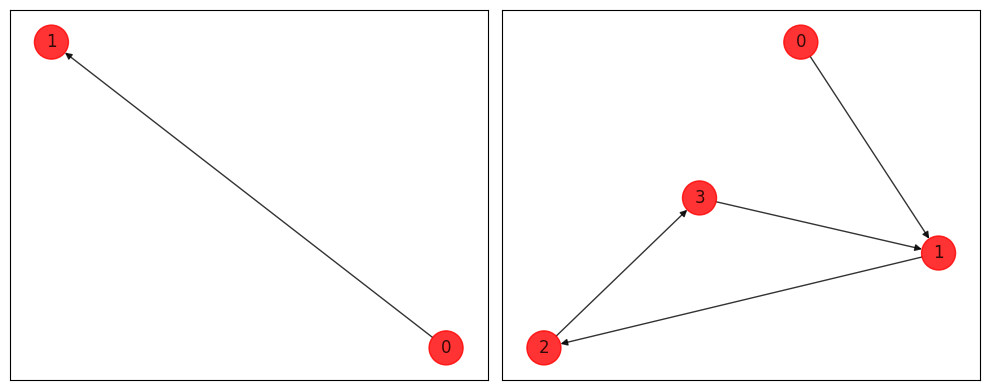

Iteration overlaps: [0.9999999907059391, 0.9999999731284155, 0.999999912890123, 0.9999998339432397, 0.9999991123254381, 0.999999927120734, 0.999999923666043, 0.9999999040168167, 0.9999998897898782, 0.9999993125870328, 0.9999999791236313, 0.9999999691822086, 0.9999999040283271, 0.9544464622911946, 0.9999999522812607, 0.9999999562794284, 0.9999999247302561, 0.9999999779226502, 0.9999998461086991, 0.9999998878180634]
Iteration timings: [10.595596300001489, 7.665337999991607, 9.38678230001824, 7.196122099994682, 5.218457599985413, 7.2890918999910355, 9.517367299995385, 5.818711900006747, 18.375420700001996, 6.724692000017967, 16.081459100008942, 7.744259300001431, 8.825501200015424, 7.176601700019091, 6.652629499993054, 8.519881100015482, 8.672261600004276, 17.70075540000107, 9.449429300002521, 7.837195799977053]
Average overlap: 0.997722181996969, Average timing: 9.322377705002145


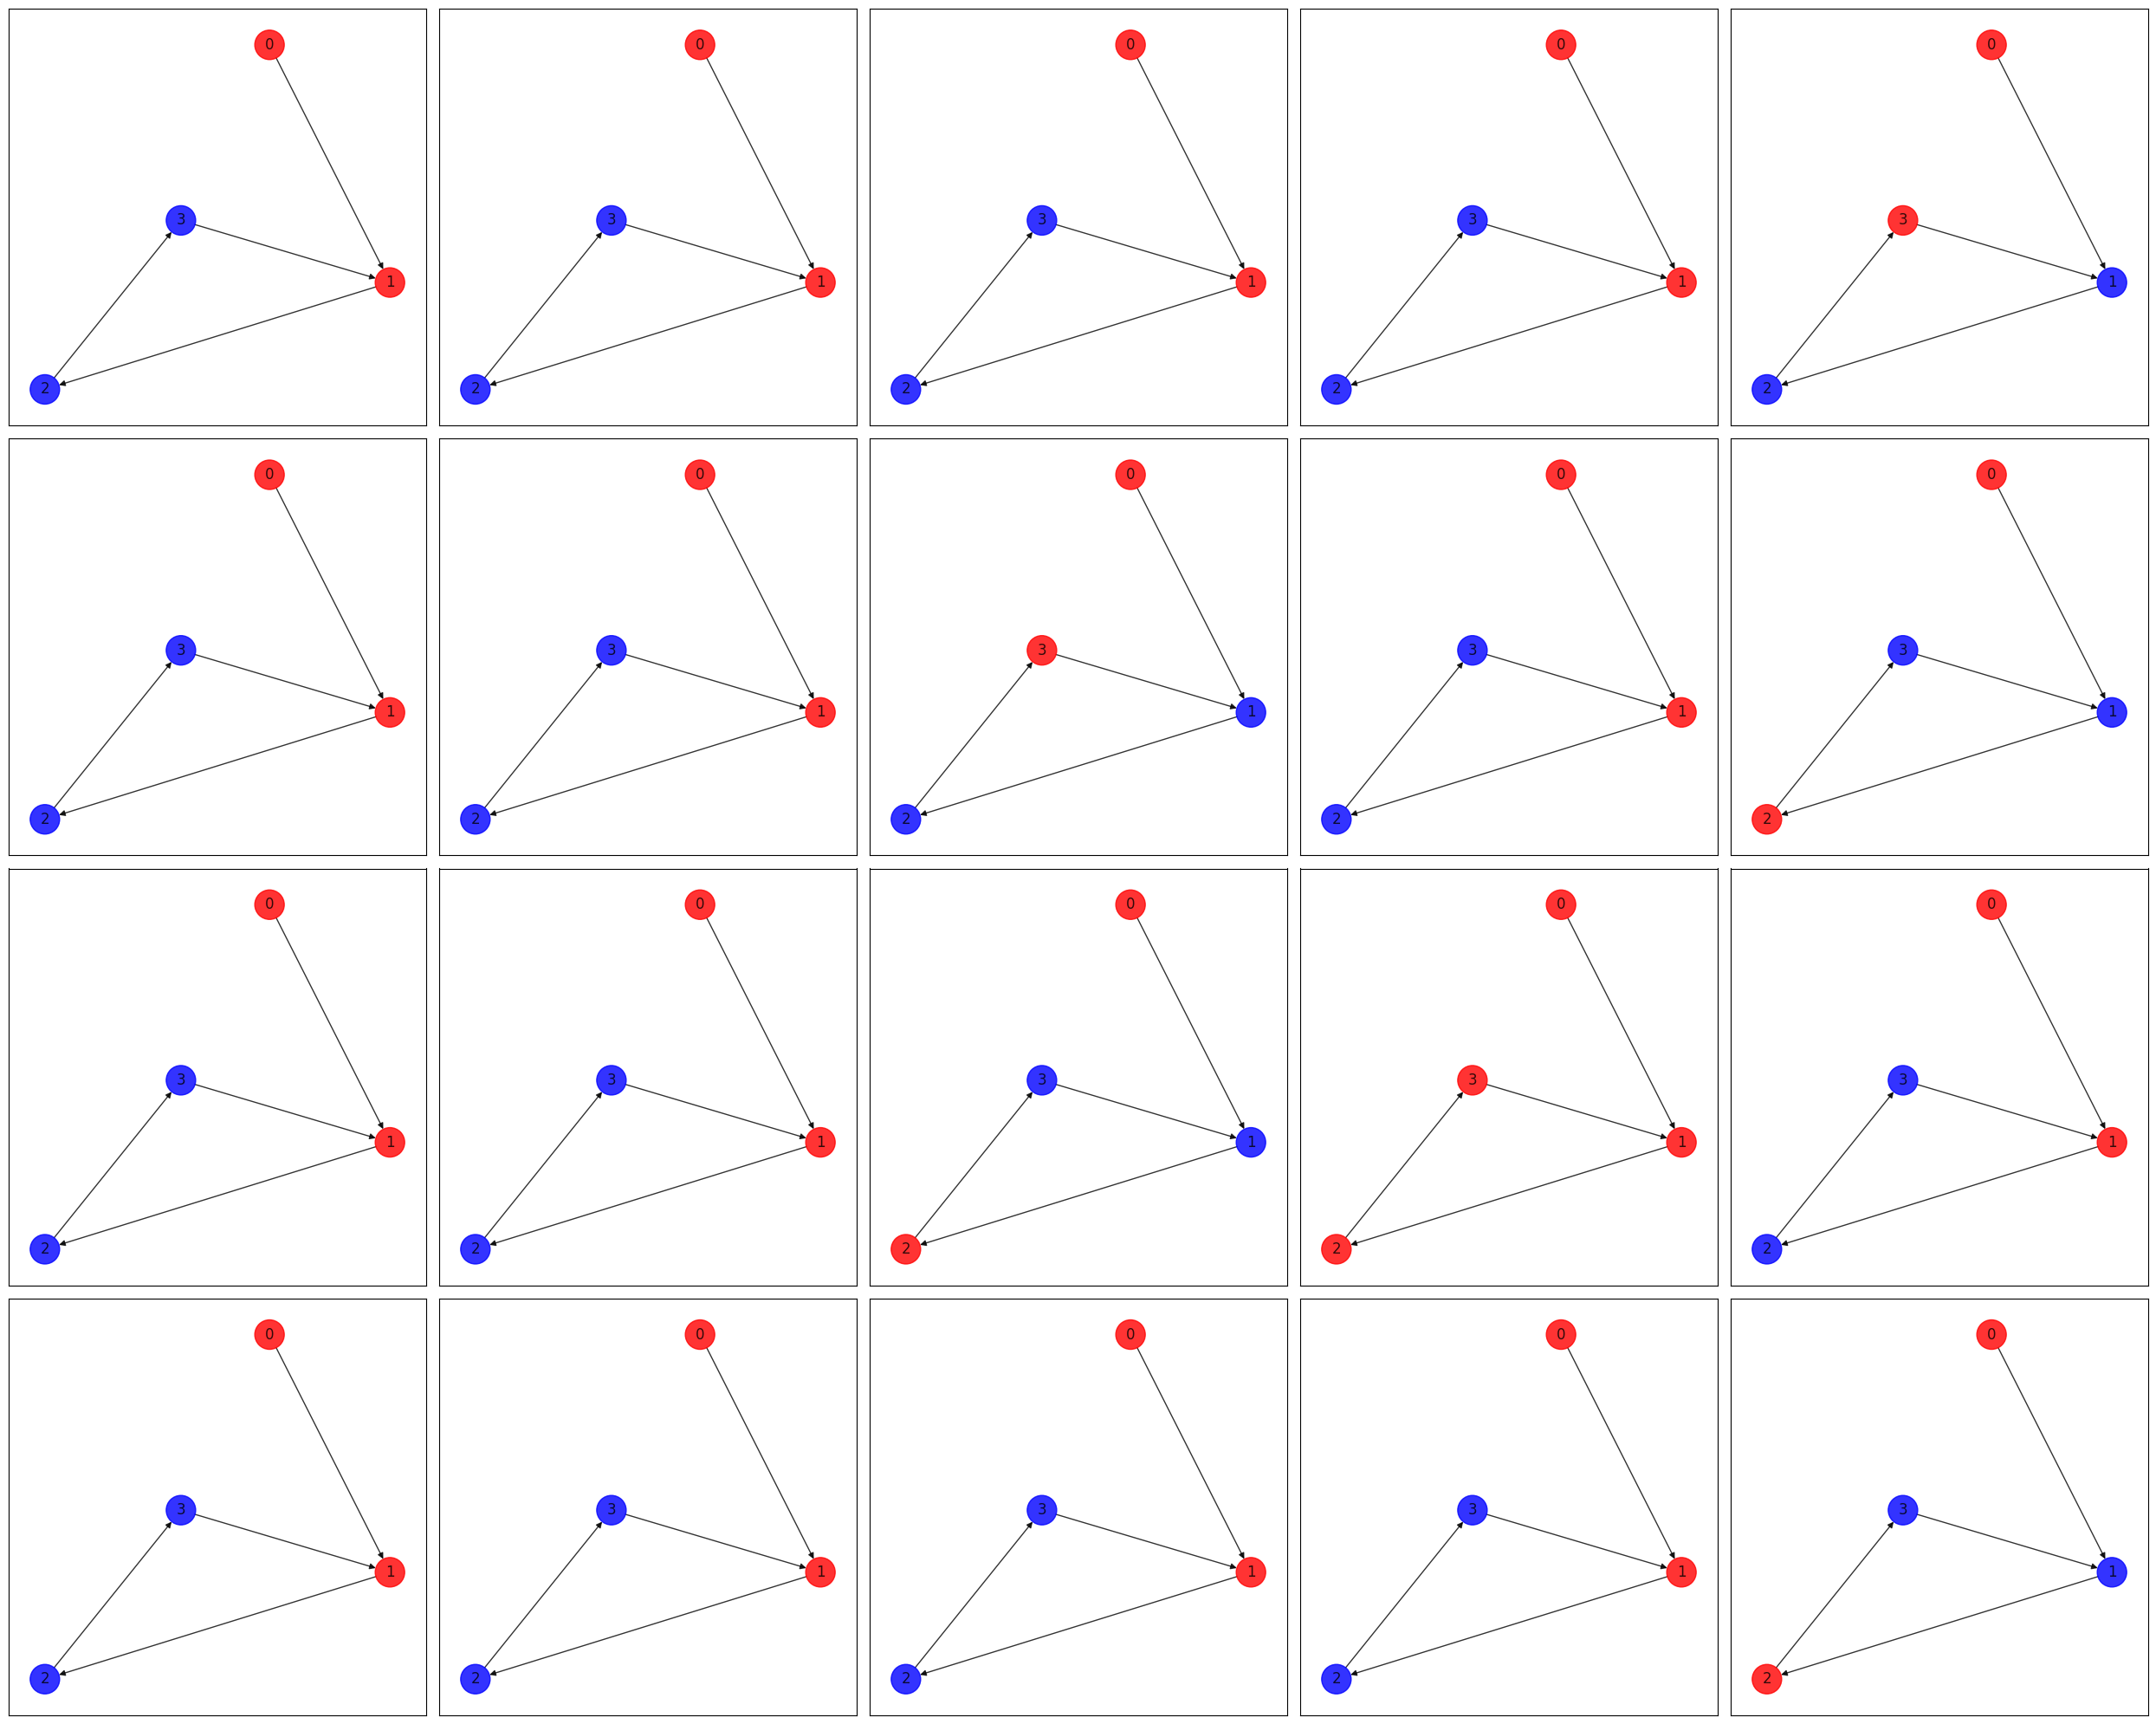

In [32]:
# Target graph:
m = 4  # Number of nodes in graph
H = nx.DiGraph()
H.add_nodes_from(np.arange(0, m, 1))
elistH = [(0, 1), (1, 2), (2, 3), (3, 1)]   # <- defines graph structure
H.add_edges_from(elistH)
colorsH = ["r" for node in H.nodes()]
posH = nx.spring_layout(H)

# Pattern graph:
n = 2
G = nx.DiGraph()
G.add_nodes_from(np.arange(0, n, 1))
elistG = [(0, 1)]                           # <- defines graph structure
G.add_edges_from(elistG)
colorsG = ["r" for node in G.nodes()]
posG = nx.spring_layout(H)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
draw_graph(G, colorsG, posG, axes[0])
draw_graph(H, colorsH, posH, axes[1])

plt.tight_layout()
plt.show()

run_experiment(m, H, posH, n, G)

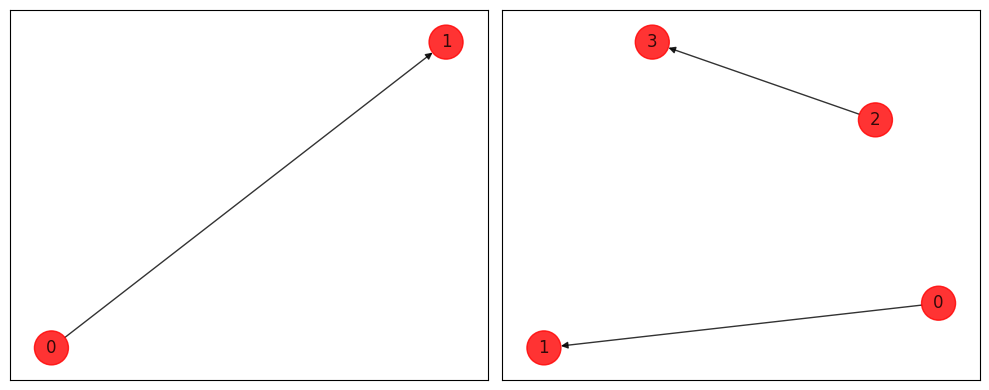

Iteration overlaps: [0.9999997353797492, 0.9999992559217298, 0.9999999619245042, 0.9999997741521124, 0.9999999719190014, 0.9999999360208806, 0.49999998446907373, 0.9999999662303959, 0.9999999217045741, 0.49999989954513807, 0.9999999434661234, 0.9999999477649602, 0.9999999577380541, 0.9999997710065704, 0.9999998911309854, 0.999999834149057, 0.9999999962373498, 0.9999997213333273, 0.9999999476242363, 0.9999979407346505]
Iteration timings: [5.451728899992304, 6.785362900001928, 6.568603399995482, 6.640786199975992, 7.475482399982866, 8.702289999986533, 10.474669599992922, 5.503442500019446, 5.4460382999968715, 7.060404799995013, 5.047078100004001, 4.931140500004403, 6.124218700017082, 7.950268799992045, 8.083750100020552, 6.11582289999933, 8.199760499992408, 8.179832399997395, 7.89993250000407, 5.939321799989557]
Average overlap: 0.9499997679226239, Average timing: 6.9289967649980095


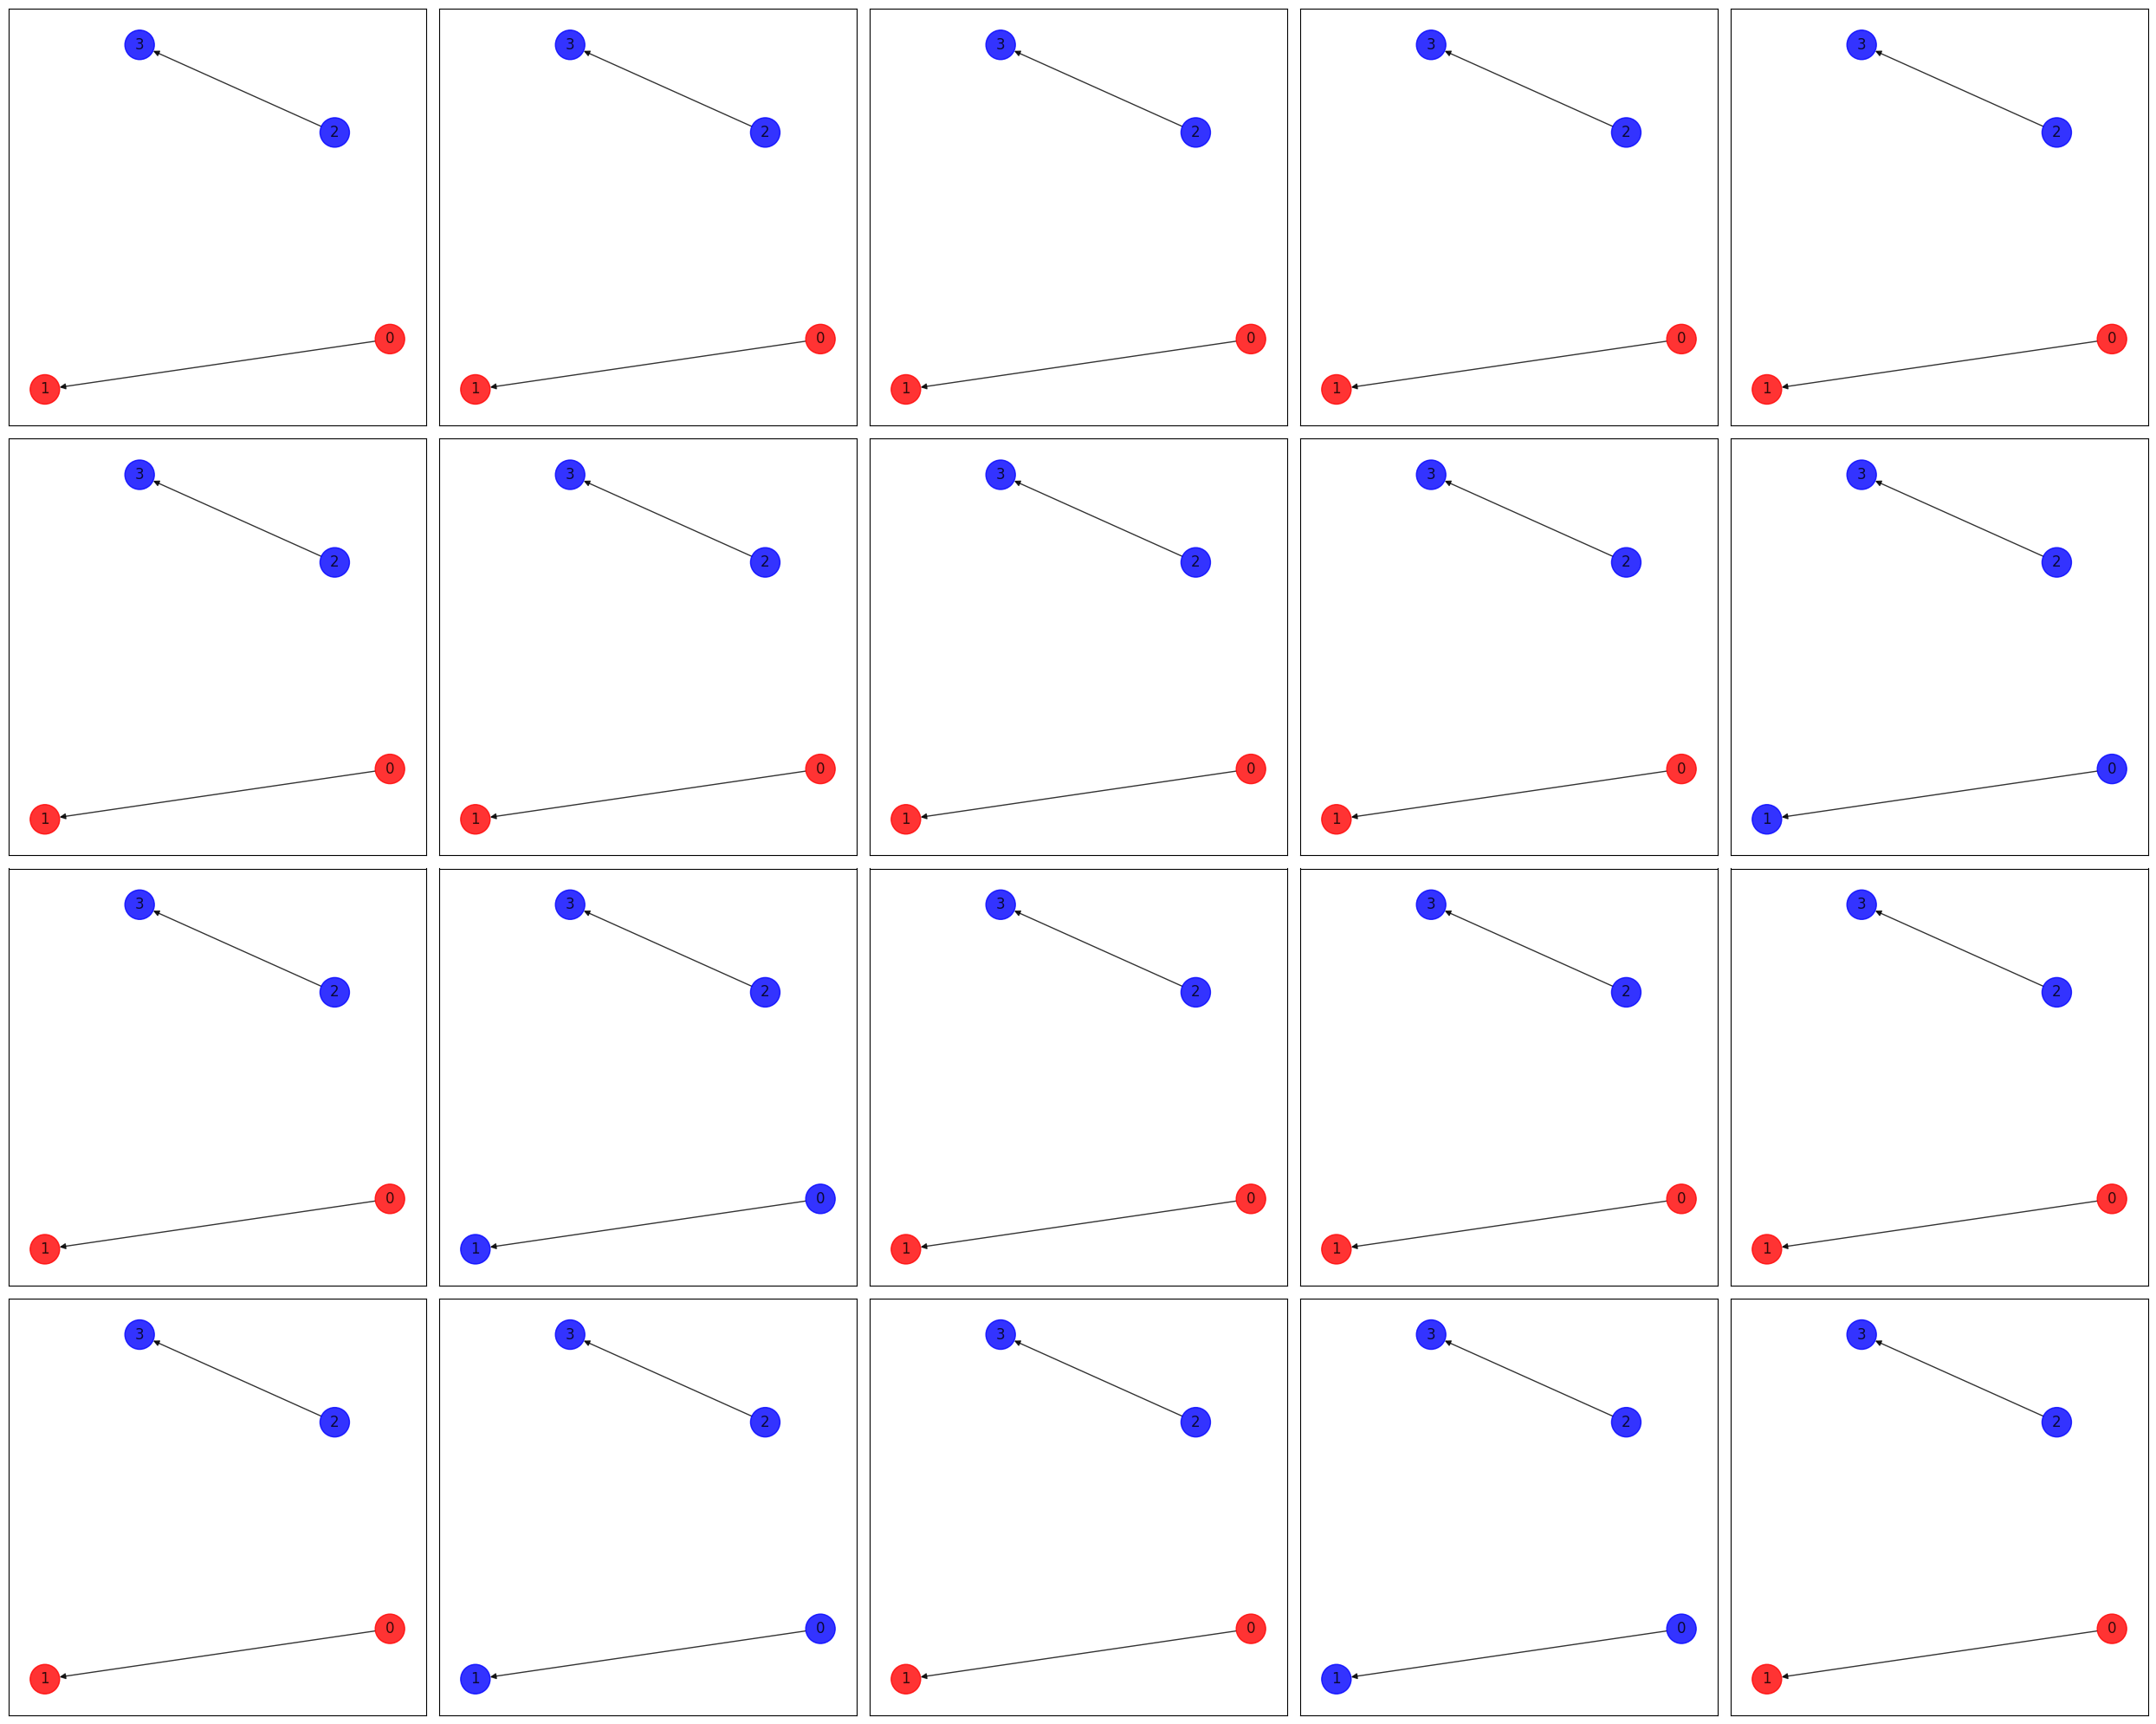

In [33]:
# Target graph:
m = 4  # Number of nodes in graph
H = nx.DiGraph()
H.add_nodes_from(np.arange(0, m, 1))
elistH = [(0, 1), (2, 3)]   # <- defines graph structure
H.add_edges_from(elistH)
colorsH = ["r" for node in H.nodes()]
posH = nx.spring_layout(H)

# Pattern graph:
n = 2
G = nx.DiGraph()
G.add_nodes_from(np.arange(0, n, 1))
elistG = [(0, 1)]                           # <- defines graph structure
G.add_edges_from(elistG)
colorsG = ["r" for node in G.nodes()]
posG = nx.spring_layout(H)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
draw_graph(G, colorsG, posG, axes[0])
draw_graph(H, colorsH, posH, axes[1])

plt.tight_layout()
plt.show()

run_experiment(m, H, posH, n, G)